# 01 · Base de conhecimento e busca

Este notebook cobre a primeira metade do pipeline do Luz Segura:

1. a base de conhecimento (documentos, fontes, licenças e trechos);
2. a partição dos trechos entre treino, dev e teste;
3. os casos de avaliação com gabarito, incluindo os que **não constam** na base;
4. a busca: comparação de três modelos de embeddings no dev, resultado do escolhido no teste (recall@1 e recall@3);
5. a escolha do limiar de similaridade abaixo do qual o assistente recusa sem chamar o modelo.

Não precisa de GPU nem do servidor do modelo. Na primeira execução, os três modelos de embeddings são baixados do Hugging Face (o bge-m3 tem cerca de 2,3 GB). Para reproduzir:
`uv run jupyter nbconvert --to notebook --execute --inplace notebooks/01_base_e_busca.ipynb`

In [1]:
import json
import os
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.filterwarnings("ignore")

from luz_segura.evaluation import full_coverage_at, load_cases, recall_at, retrieval_results
from luz_segura.knowledge_base import load_chunks, read_documents, sources_table
from luz_segura.retrieval import EMBEDDING_MODELS, Retriever
from luz_segura.split import load_split

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

## 1. Base de conhecimento

Cada documento de `base/documentos/` é um Markdown com cabeçalho de metadados (fonte, órgão, endereço, formato original, tipo, licença e data de acesso). Cada seção `##` vira um trecho de no máximo 250 palavras e pode ter o próprio endereço de origem. O comando `python -m luz_segura.knowledge_base` gera `base/trechos.jsonl`, `base/fontes.csv` e `base/fontes.md`.

Há cinco tipos de documento, e o tipo define como o texto entra na base:

- **ato oficial, transcrição literal**: Constituição, leis, decreto e resolução da ANEEL. Atos oficiais não têm proteção de direito autoral (Lei 9.610/1998, art. 8º, IV).
- **página gov.br, transcrição literal**: páginas da ANEEL e do Ministério das Cidades sob CC BY-ND 3.0. Por isso o texto entra sem alteração e com crédito.
- **publicação com permissão de reprodução parcial**: o Guia de PPP de Iluminação Pública do Banco Mundial (todos os direitos reservados, com permissão de reproduzir partes citando a fonte). Entra como trecho curto e literal, com a fonte.
- **ficha em redação própria**: fatos de páginas sem licença aberta (Osasco Digital, Central 156, Enel), contados com palavras próprias, com link e data de acesso.
- **documento do produto**: como o Luz Segura funciona (relato, foto, prioridade, privacidade e assistente).

In [2]:
documents = read_documents()
chunks = load_chunks()
by_id = {c.id: c for c in chunks}
words = Counter()
for c in chunks:
    words[c.document] += c.word_count

DOCUMENT_TYPES = ("ato oficial", "página gov.br", "publicação com permissão", "ficha em redação própria", "documento do produto")


def document_type(kind):
    # o campo kind detalha o tipo (por exemplo, "ficha em redação própria (resumo em linguagem simples)")
    return next(t for t in DOCUMENT_TYPES if kind.startswith(t))


table = pd.DataFrame(sources_table(documents, chunks))
table["palavras"] = table["document"].map(words)
table["tipo"] = table["kind"].map(document_type)
print(f"{len(documents)} documentos, {len(chunks)} trechos, {sum(words.values())} palavras")
sizes = sorted(c.word_count for c in chunks)
print(f"palavras por trecho: mínimo {sizes[0]}, mediana {sizes[len(sizes) // 2]}, máximo {sizes[-1]}")
table[["document", "publisher", "original_format", "tipo", "chunks", "palavras"]].rename(columns={
    "document": "documento", "publisher": "órgão", "original_format": "formato original", "chunks": "trechos"})

26 documentos, 76 trechos, 6927 palavras
palavras por trecho: mínimo 31, mediana 83, máximo 212


,documento,órgão,formato original,tipo,trechos,palavras
0,aneel-distribuidoras,"Agência Nacional de Energia Elétrica (ANEEL), portal gov.br",HTML,página gov.br,1,38
1,aneel-iluminacao,"Agência Nacional de Energia Elétrica (ANEEL), portal gov.br",HTML,página gov.br,1,184
2,cf88,Presidência da República (portal da legislação do Planalto),HTML (texto compilado),ato oficial,2,161
3,cidades-vendaval,"Ministério das Cidades, portal gov.br",HTML,página gov.br,1,109
4,decreto14955-ufmo,"Prefeitura de Osasco, Imprensa Oficial do Município (IOMO nº 2938,...",PDF (diário oficial com texto extraível),ato oficial,1,87
5,ficha-cip,Redação própria do projeto Luz Segura a partir da Constituição Fed...,PDF do diário oficial e HTML,ficha em redação própria,3,287
6,ficha-distribuidora,Redação própria do projeto Luz Segura a partir de páginas da ANEEL...,HTML e PDF,ficha em redação própria,4,311
7,ficha-normas-tecnicas,Redação própria do projeto Luz Segura a partir do Catálogo ABNT e ...,HTML,ficha em redação própria,2,151
8,ficha-ouvidoria,Redação própria do projeto Luz Segura a partir da Carta de Serviço...,Página HTML que exige JavaScript (Carta de Serviços) e HTML estáti...,ficha em redação própria,3,207
9,ficha-pedido-156,Redação própria do projeto Luz Segura a partir da Carta de Serviço...,Páginas HTML que exigem JavaScript (Carta de Serviços e Central 15...,ficha em redação própria,8,613


In [3]:
summary = table.groupby("tipo").agg(documentos=("document", "count"), trechos=("chunks", "sum"), palavras=("palavras", "sum"))
summary.sort_values("trechos", ascending=False)

,documentos,trechos,palavras
tipo,,,
ficha em redação própria,9,31,2445
ato oficial,7,24,2738
documento do produto,6,17,1248
página gov.br,3,3,331
publicação com permissão,1,1,165


Licença de cada documento (a tabela completa, com todos os endereços, inclusive os próprios de cada seção, está em `base/fontes.md`):

In [4]:
table[["document", "license"]].rename(columns={"document": "documento", "license": "licença"})

,documento,licença
0,aneel-distribuidoras,Creative Commons Atribuição-SemDerivações 3.0 Não Adaptada (CC BY-...
1,aneel-iluminacao,Creative Commons Atribuição-SemDerivações 3.0 Não Adaptada (CC BY-...
2,cf88,"Ato oficial sem proteção de direito autoral (Lei 9.610/1998, art. ..."
3,cidades-vendaval,Creative Commons Atribuição-SemDerivações 3.0 Não Adaptada (CC BY-...
4,decreto14955-ufmo,"Ato oficial sem proteção de direito autoral (Lei 9.610/1998, art. ..."
5,ficha-cip,Texto do projeto
6,ficha-distribuidora,"Texto do projeto; fatos de páginas sem licença aberta (Enel, todos..."
7,ficha-normas-tecnicas,Texto do projeto; o texto das normas ABNT é pago e não é reproduzido
8,ficha-ouvidoria,Texto do projeto; as fontes não trazem licença aberta (Osasco Digi...
9,ficha-pedido-156,Texto do projeto; as fontes não permitem reprodução (Osasco Digita...


Exemplo de trecho, no formato que a busca indexa (`documento > seção`, depois o texto):

In [5]:
print(by_id["ren1000-02"].indexed_text)
print("\nfonte:", by_id["ren1000-02"].url)

REN ANEEL 1.000/2021 > Art. 451: responsabilidade pela iluminação pública
Art. 451. A elaboração de projeto, a implantação, expansão, operação e manutenção das instalações de iluminação pública são de responsabilidade do poder público municipal.
§ 1º A distribuidora pode prestar os serviços dispostos no caput mediante celebração de contrato específico para tal fim, ficando a pessoa jurídica de direito público responsável pelas despesas decorrentes.
§ 2º A responsabilidade do poder público municipal inclui os custos de ampliação de capacidade ou reforma de subestações, alimentadores e linhas já existentes, desde que necessárias ao atendimento das instalações de iluminação pública, devendo ser realizado o cálculo do encargo de responsabilidade da distribuidora disposto no Capítulo II do Título I.

fonte: https://leis.org/institucionais/br/aneel/lei/resolucao-normativa/2021/1000/resolucao-normativa-n-1000-2021-estabelece-as-regras-de-prestacao-do-servico-publico-de-distribuicao-de-energia

## 2. Partição dos trechos

Os trechos foram sorteados (semente 2026) com proporções-alvo de 50% para treino, 20% para dev e 30% para teste, de forma estratificada por documento: todo documento com dois ou mais trechos tem pelo menos um no teste, e os documentos de um trecho só são sorteados juntos. Com o arredondamento por documento, o resultado é o da tabela abaixo. O LoRA só vê trechos de treino. Dev serve para ajustes (escolha do modelo de embeddings, limiar, época do LoRA), e o teste só é usado no placar final.

In [6]:
split = load_split()
counts = Counter(split.values())
print({name: f"{counts[name]} ({counts[name] / len(split):.0%})" for name in ("train", "dev", "test")})
per_doc = pd.crosstab(pd.Series([by_id[i].document for i in split], name="documento"),
                      pd.Series(list(split.values()), name="partição"))
per_doc[["train", "dev", "test"]].T

{'train': '35 (46%)', 'dev': '16 (21%)', 'test': '25 (33%)'}


documento,aneel-distribuidoras,aneel-iluminacao,cf88,cidades-vendaval,decreto14955-ufmo,ficha-cip,ficha-distribuidora,ficha-normas-tecnicas,ficha-ouvidoria,ficha-pedido-156,...,lc448-delegacao,lc464-estrutura,lei13460,produto-assistente,produto-foto,produto-prioridade,produto-privacidade,produto-relato,produto-sobre,ren1000
partição,,,,,,,,,,,,,,,,,,,,,
train,0,0,1,0,1,1,2,1,1,4,...,1,1,2,1,1,1,1,1,1,4
dev,0,1,0,0,0,1,1,0,1,2,...,0,0,1,0,1,1,1,1,1,1
test,1,0,1,1,0,1,1,1,1,2,...,0,1,1,1,1,1,1,1,1,2


## 3. Casos de avaliação

`avaliacao/build_cases.py` gera os casos de teste (60) e de dev (40). Cada caso traz a pergunta, o desfecho esperado (`answer` ou `refuse`), a resposta de referência, os pontos-chave que a resposta precisa conter, padrões proibidos (erros típicos, que só contam quando afirmados), os trechos que contêm a resposta e uma citação literal de evidência. O script confere se cada citação existe no trecho indicado e se o trecho principal (o primeiro de evidência) é da mesma partição do caso.

Os casos `refuse` são perguntas cuja resposta **não consta** na base, e cada um traz a justificativa (`why_absent`): o que a pergunta pede, o trecho mais próximo da base por conteúdo (nos casos perto do tema, em geral a isca usada ao montar o caso; nem sempre é o primeiro da busca) e o que falta nele. O campo `refusal_reason` classifica o motivo:

| refusal_reason | significado |
|---|---|
| `absent_fact` | o tema está na base, mas o dado pedido não |
| `other_city` | pergunta sobre outra cidade |
| `individual_case` | situação de um pedido específico (protocolo, agendamento) |
| `out_of_domain` | fora do tema do assistente |
| `injection` | instrução embutida para manipular o assistente |
| `personal_data` | pedido de contato pessoal ou com dado pessoal |

O campo `decoy_chunk` é só informativo: o trecho parecido com a pergunta que serviu de isca ao montar o caso.

In [7]:
test_cases = load_cases("casos_teste.jsonl")
dev_cases = load_cases("casos_dev.jsonl")
cases_table = pd.DataFrame([{"partição": c["split"], "categoria": c["category"], "esperado": c["expected"]}
                            for c in test_cases + dev_cases])
pd.crosstab([cases_table["esperado"], cases_table["categoria"]], cases_table["partição"], margins=True, margins_name="total")

partição                     dev  test  total
esperado categoria                           
answer   adversarial_answer    0     2      2
         direct_fact          13    10     23
         electrical_risk       2     5      7
         paraphrase            4    10     14
         partial               1     2      3
         procedure             3     6      9
         two_chunks            1     4      5
refuse   adversarial_refuse    2     2      4
         near_miss            10    14     24
         out_of_domain         4     5      9
total                         40    60    100

In [8]:
for case_id in ("t13", "t36", "t49", "t59"):
    c = next(x for x in test_cases if x["id"] == case_id)
    print(f"{c['id']} [{c['category']}, esperado: {c['expected']}]\n  pergunta: {c['question']}\n  gabarito: {c['reference_answer']}")
    if c["evidence"]:
        print(f"  evidência ({c['evidence'][0][0]}): \"{c['evidence'][0][1]}\"")
    if c.get("why_absent"):
        print(f"  por que não consta ({c['refusal_reason']}): {c['why_absent']}")
    print()

t13 [paraphrase, esperado: answer]
  pergunta: tem algum prazo maximo pra prefeitura arrumar a lampada?
  gabarito: Não há prazo máximo publicado: a Carta de Serviços deixa o campo de prazo sem número, e nenhuma lei ou decreto municipal consultado fixa prazo de reparo.
  evidência (ficha-prazos-02): "não informa prazo máximo para os serviços de iluminação pública"

t36 [partial, esperado: answer]
  pergunta: Quantos pedidos de iluminação a Central 156 recebeu em 2023 e quantos recebeu em 2025?
  gabarito: Em 2023 foram 11.046 pedidos de iluminação pública; o número de 2025 não consta na base.
  evidência (ficha-pedido-156-08): "com 11.046 pedidos no ano"

t49 [near_miss, esperado: refuse]
  pergunta: Qual é o horário de atendimento do WhatsApp (11) 3651-7080?
  gabarito: Não consta na base de conhecimento.
  por que não consta (absent_fact): Pede o horário de atendimento do WhatsApp (11) 3651-7080. O trecho mais próximo, ficha-pedido-156-02, lista os canais da Central 156 e diz que o t

Alguns casos aceitam como evidência, além do trecho principal, trechos de outra partição que repetem o mesmo fato (por exemplo, o telefone de emergência da Enel aparece em vários documentos). Os casos de teste com algum trecho de treino entre as alternativas de evidência ficam marcados aqui, porque o LoRA pode ter visto o mesmo fato no treino. O notebook 04 mostra o placar também sem eles.

In [9]:
train_chunks = {chunk_id for chunk_id, part in split.items() if part == "train"}
overlap = [c["id"] for c in test_cases if c["expected"] == "answer" and any(g in train_chunks for group in c["gold_chunks"] for g in group)]
print(f"{len(overlap)} de {sum(c['expected'] == 'answer' for c in test_cases)} casos de teste respondíveis aceitam algum trecho de treino como evidência:")
print(overlap)

12 de 39 casos de teste respondíveis aceitam algum trecho de treino como evidência:
['t01', 't02', 't07', 't16', 't19', 't23', 't26', 't29', 't30', 't31', 't34', 't39']


## 4. Busca

A busca é densa: cada trecho (`documento > seção` + texto) vira um vetor, e a pergunta é comparada a todos os trechos por similaridade de cosseno. Roda em CPU. O assistente usa os k = 3 trechos mais parecidos.

**recall@k** é a média, por pergunta respondível, da fração de grupos de evidência com algum trecho entre os k primeiros. Uma pergunta que precisa de dois trechos conta meio ponto se só um deles aparece. **Cobertura@3** é quantas perguntas têm toda a evidência entre os 3 primeiros, o teto de acerto do RAG.

### 4.1 Escolha do modelo de embeddings (dev)

Três modelos multilíngues abertos, comparados só nas perguntas respondíveis do dev. Regra: vence o de maior recall@3, desde que atinja recall@3 ≥ 0,90 e recall@1 ≥ 0,70. O tempo por pergunta em CPU entra como critério de desempate.

In [10]:
ids = [c.id for c in chunks]
dev_answer = [c for c in dev_cases if c["expected"] == "answer"]
comparison, retrievers = [], {}
for key, spec in EMBEDDING_MODELS.items():
    start = time.perf_counter()
    retriever = Retriever(chunks, spec)
    load_s = time.perf_counter() - start
    retriever.scores(["pergunta de aquecimento"])  # a primeira chamada inclui inicialização
    start = time.perf_counter()
    matrix = retriever.scores([c["question"] for c in dev_answer])
    query_ms = 1000 * (time.perf_counter() - start) / len(dev_answer)
    results = retrieval_results(dev_answer, matrix, ids)
    covered, total = full_coverage_at(results, 3)
    comparison.append({"modelo": spec.model_name, "versão": spec.revision[:10], "recall@1": recall_at(results, 1),
                       "recall@3": recall_at(results, 3), "recall@5": recall_at(results, 5), "cobertura@3": f"{covered}/{total}",
                       "ms por pergunta": round(query_ms)})
    misses = [(r.case_id, r.top_ids[:3]) for r in results if r.groups_hit_at[3] < r.n_groups]
    print(f"{key}: falhas no top-3 -> {misses}")
    if key == "bge-m3":
        retrievers[key] = retriever
    else:
        del retriever
comparison = pd.DataFrame(comparison)
comparison.round(3)

e5-small: falhas no top-3 -> [('d06', ['ficha-responsaveis-02', 'ficha-pedido-156-01', 'ficha-cip-01']), ('d13', ['produto-relato-03', 'ficha-pedido-156-04', 'produto-sobre-02']), ('d17', ['produto-sobre-01', 'produto-foto-03', 'produto-relato-03']), ('d24', ['produto-foto-03', 'lc464-estrutura-02', 'lei13460-01'])]


granite-97m: falhas no top-3 -> [('d06', ['ficha-pedido-156-01', 'ficha-responsaveis-02', 'lc404-cip-01']), ('d11', ['aneel-iluminacao-01', 'ren1000-05', 'ficha-responsaveis-01']), ('d17', ['produto-sobre-01', 'produto-relato-03', 'produto-privacidade-03']), ('d24', ['produto-privacidade-01', 'produto-foto-03', 'produto-relato-03'])]


bge-m3: falhas no top-3 -> [('d11', ['aneel-iluminacao-01', 'ren1000-04', 'ficha-responsaveis-01'])]


,modelo,versão,recall@1,recall@3,recall@5,cobertura@3,ms por pergunta
0,intfloat/multilingual-e5-small,614241f622,0.583,0.833,0.833,20/24,4
1,ibm-granite/granite-embedding-97m-multilingual-r2,835ad14087,0.646,0.833,0.917,20/24,5
2,BAAI/bge-m3,5617a9f61b,0.771,0.958,1.000,23/24,38


O **BAAI/bge-m3** (licença MIT) é o único que passa das duas metas e fica bem à frente nos dois recalls. É o mais lento dos três (coluna "ms por pergunta", medida em lote com as perguntas do dev), mas a diferença é de dezenas de milissegundos, pouco perto dos cerca de 2 s por pergunta da geração (notebook 02). A única falha no top-3 do dev é a d11 (iluminação de vias internas de condomínios). O trecho certo (`ren1000-01`, art. 450) perde para trechos que falam de iluminação pública de forma mais geral.

### 4.2 Resultado no teste

Com o modelo escolhido, a busca roda uma vez nas perguntas respondíveis do teste:

In [11]:
retriever = retrievers["bge-m3"]
test_answer = [c for c in test_cases if c["expected"] == "answer"]
test_matrix = retriever.scores([c["question"] for c in test_answer])
test_results = retrieval_results(test_answer, test_matrix, ids)
covered, total = full_coverage_at(test_results, 3)
search_test = {"perguntas": len(test_answer), "recall@1": round(recall_at(test_results, 1), 3),
               "recall@3": round(recall_at(test_results, 3), 3), "recall@5": round(recall_at(test_results, 5), 3),
               "cobertura@3": f"{covered}/{total}"}
print(search_test)
by_category = pd.DataFrame([{"categoria": c["category"], "recall@1": r.groups_hit_at[1] / r.n_groups,
                             "recall@3": r.groups_hit_at[3] / r.n_groups} for c, r in zip(test_answer, test_results)])
by_category.groupby("categoria").agg(perguntas=("recall@1", "size"), **{"recall@1": ("recall@1", "mean"), "recall@3": ("recall@3", "mean")}).round(3)

{'perguntas': 39, 'recall@1': 0.769, 'recall@3': 0.962, 'recall@5': 0.974, 'cobertura@3': '37/39'}


,perguntas,recall@1,recall@3
categoria,,,
adversarial_answer,2,1.000,1.000
direct_fact,10,0.800,0.900
electrical_risk,5,0.800,1.000
paraphrase,10,0.800,1.000
partial,2,1.000,1.000
procedure,6,0.667,1.000
two_chunks,4,0.500,0.875


In [12]:
for case, result in zip(test_answer, test_results):
    if result.groups_hit_at[3] < result.n_groups:
        print(f"{case['id']} [{case['category']}] {case['question']}\n   esperado: {case['gold_chunks']}\n   top-3: {result.top_ids[:3]}")

t08 [direct_fact] Quantos caracteres tem o código que o relato recebe no Luz Segura?
   esperado: [['produto-relato-01']]
   top-3: ['produto-relato-03', 'produto-sobre-03', 'produto-privacidade-01']
t32 [two_chunks] Onde fica a sede da Enel São Paulo e qual é o número do contrato de concessão que inclui Osasco?
   esperado: [['aneel-distribuidoras-01'], ['ficha-distribuidora-01']]
   top-3: ['ficha-distribuidora-01', 'ficha-distribuidora-02', 'ficha-distribuidora-03']


## 5. Limiar de similaridade

Se a maior similaridade entre a pergunta e os trechos (s1) fica abaixo de um limiar τ, o assistente recusa sem chamar o modelo. Isso economiza geração e serve de rede para perguntas claramente fora do tema. O limiar é escolhido só com perguntas de **dev e de treino**. As perguntas de treino que a descontaminação descartou por serem parecidas com casos de teste ou de dev (lista `dropped` de `treino/composicao.json`) também ficam de fora aqui, para nenhuma gêmea de pergunta do teste influenciar o limiar.

O custo dos erros não é simétrico. Recusar uma pergunta que a base responde deixa o morador sem a informação. Já a pergunta sem resposta que passa pelo limiar ainda tem outra barreira, porque o modelo também pode recusar: no dev, o modelo base com os trechos recusou sozinho todas as 16 perguntas sem resposta (notebook 02, placar do gerador isolado, sem o limiar). Por isso a regra é conservadora: **τ é o maior valor, em centésimos, que fica pelo menos 0,01 abaixo do menor s1 entre as perguntas respondíveis de dev e de treino**.

In [13]:
source = json.loads((ROOT / "treino" / "perguntas_treino.json").read_text(encoding="utf-8"))
dropped = {d["question"] for d in json.loads((ROOT / "treino" / "composicao.json").read_text(encoding="utf-8"))["dropped"]}
kept_qa = [q["question"] for q in source["qa"] if q["question"] not in dropped]
kept_refusals = [r for r in source["refusals"] if r["question"] not in dropped]
print(f"perguntas de treino: {len(source['qa'])} respondíveis e {len(source['refusals'])} sem resposta; "
      f"{len(dropped)} descartadas pela descontaminação ficam de fora")
groups = {
    "respondíveis (dev)": [c["question"] for c in dev_cases if c["expected"] == "answer"],
    "respondíveis (treino)": kept_qa,
    "sem resposta, perto do tema (dev + treino)": [c["question"] for c in dev_cases if c["category"] == "near_miss"]
        + [r["question"] for r in kept_refusals if r["kind"] == "near_domain"],
    "fora do tema (dev + treino)": [c["question"] for c in dev_cases if c["category"] == "out_of_domain"]
        + [r["question"] for r in kept_refusals if r["kind"] == "out_of_domain"],
    "manipulação (dev + treino)": [c["question"] for c in dev_cases if c["category"] == "adversarial_refuse"]
        + [r["question"] for r in kept_refusals if r["kind"] == "improper"],
}
s1 = {name: retriever.scores(questions).max(axis=1) for name, questions in groups.items()}
pd.DataFrame([{"grupo": name, "perguntas": len(v), "mínimo": v.min(), "p05": np.percentile(v, 5), "mediana": np.median(v),
               "máximo": v.max()} for name, v in s1.items()]).round(3)

perguntas de treino: 175 respondíveis e 80 sem resposta; 40 descartadas pela descontaminação ficam de fora


,grupo,perguntas,mínimo,p05,mediana,máximo
0,respondíveis (dev),24,0.542,0.551,0.664,0.791
1,respondíveis (treino),158,0.431,0.534,0.632,0.778
2,"sem resposta, perto do tema (dev + treino)",38,0.455,0.498,0.605,0.686
3,fora do tema (dev + treino),18,0.219,0.303,0.464,0.555
4,manipulação (dev + treino),17,0.415,0.425,0.567,0.749


In [14]:
answerable_questions = groups["respondíveis (dev)"] + groups["respondíveis (treino)"]
answerable = np.concatenate([s1["respondíveis (dev)"], s1["respondíveis (treino)"]])
threshold = round(float(np.floor(100 * (float(answerable.min()) - 0.01))) / 100, 2)
print(f"menor s1 entre respondíveis: {answerable.min():.3f} -> τ = {threshold:.2f}\n")
print("respondíveis de menor s1:")
for i in np.argsort(answerable)[:5]:
    print(f"   {answerable[i]:.3f}  {answerable_questions[i]}")
candidates = []
for tau in (0.40, 0.42, 0.44, 0.46, 0.48, 0.50, 0.52, 0.55):
    candidates.append({"τ": tau, "respondíveis recusadas": f"{int((answerable < tau).sum())}/{len(answerable)}",
                       **{name.split(" (")[0]: f"{int((v < tau).sum())}/{len(v)}" for name, v in s1.items() if not name.startswith("respondíveis")}})
pd.DataFrame(candidates)

menor s1 entre respondíveis: 0.431 -> τ = 0.42

respondíveis de menor s1:
   0.431  fator de uniformidade P2
   0.440  Decreto 14.078/2024
   0.445  Decreto 14.955 faz o quê?
   0.450  transporte coletivo é serviço essencial?
   0.462  Art. 456 REN 1.000, o que diz?


,τ,respondíveis recusadas,"sem resposta, perto do tema",fora do tema,manipulação
0,0.40,0/182,0/38,7/18,0/17
1,0.42,0/182,0/38,7/18,1/17
2,0.44,2/182,0/38,7/18,2/17
3,0.46,4/182,1/38,9/18,3/17
4,0.48,5/182,2/38,10/18,4/17
5,0.50,5/182,2/38,11/18,5/17
6,0.52,6/182,6/38,15/18,6/17
7,0.55,15/182,11/38,16/18,7/17


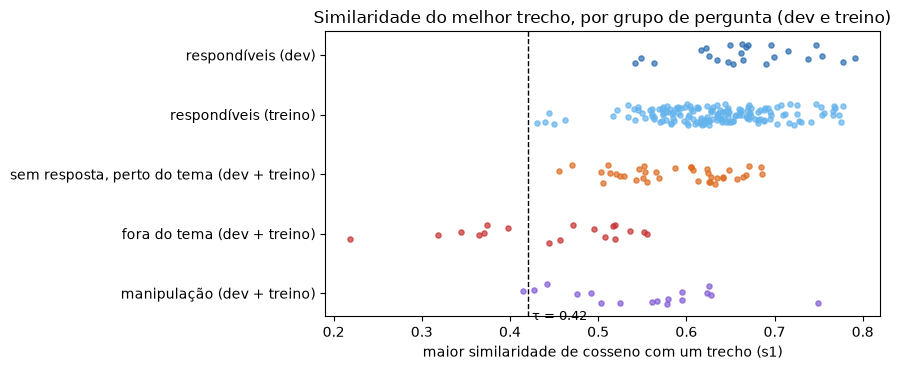

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = ["#2b6cb0", "#63b3ed", "#dd6b20", "#c53030", "#805ad5"]
for row, ((name, values), color) in enumerate(zip(s1.items(), colors)):
    jitter = np.random.default_rng(row).uniform(-0.18, 0.18, len(values))
    ax.scatter(values, row + jitter, s=14, alpha=0.7, color=color)
ax.axvline(threshold, color="black", linestyle="--", linewidth=1)
ax.text(threshold + 0.005, len(s1) - 0.55, f"τ = {threshold:.2f}", fontsize=9)
ax.set_yticks(range(len(s1)), list(s1))
ax.set_xlabel("maior similaridade de cosseno com um trecho (s1)")
ax.set_title("Similaridade do melhor trecho, por grupo de pergunta (dev e treino)")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(ROOT / "avaliacao" / "limiar.png", dpi=150)
plt.show()

As perguntas respondíveis de menor s1 são consultas curtas, quase só com o número de um ato ("Decreto 14.078/2024") ou um termo técnico ("fator de uniformidade P2"), como mostra a lista acima. Um limiar mais alto, como 0,50, barraria 11 de 18 perguntas fora do tema, mas também 5 de 182 perguntas respondíveis, justamente as curtas. Com τ = 0,42, o limiar não recusa nenhuma pergunta respondível de dev e treino e ainda barra 7 de 18 perguntas fora do tema e 1 de 17 tentativas de manipulação. As perguntas perto do tema (s1 entre 0,455 e 0,686) se misturam com as respondíveis e ficam com o modelo, que decide pelo conteúdo dos trechos.

Conferência no teste, só para registro (o limiar já estava fixado):

In [16]:
test_s1 = retriever.scores([c["question"] for c in test_cases]).max(axis=1)
check = pd.DataFrame({"esperado": [c["expected"] for c in test_cases], "categoria": [c["category"] for c in test_cases],
                      "abaixo do limiar": test_s1 < threshold})
print(check.groupby("esperado")["abaixo do limiar"].agg(["sum", "size"]).rename(columns={"sum": "abaixo de τ", "size": "perguntas"}))
print("\nabaixo de τ no teste:", [c["id"] for c, s in zip(test_cases, test_s1) if s < threshold])

          abaixo de τ  perguntas
esperado                        
answer              0         39
refuse              4         21

abaixo de τ no teste: ['t55', 't56', 't57', 't59']


In [17]:
threshold_file = ROOT / "avaliacao" / "limiar.json"
threshold_file.write_text(json.dumps({
    "threshold": float(threshold), "embedding_model": "BAAI/bge-m3", "k": 3,
    "rule": "maior valor em centésimos pelo menos 0,01 abaixo do menor s1 das perguntas respondíveis de dev e treino "
            "(sem as perguntas de treino descartadas pela descontaminação)",
    "min_answerable_s1": round(float(answerable.min()), 4), "answerable_questions": int(len(answerable)),
}, ensure_ascii=False, indent=1) + "\n", encoding="utf-8")
search_file = ROOT / "avaliacao" / "busca.json"
english = {"modelo": "model", "versão": "revision", "cobertura@3": "coverage@3", "ms por pergunta": "ms_per_question"}
search_file.write_text(json.dumps({
    "dev_comparison": comparison.rename(columns=english).round(4).to_dict(orient="records"),
    "test": {"questions": search_test["perguntas"], "recall@1": search_test["recall@1"], "recall@3": search_test["recall@3"],
             "recall@5": search_test["recall@5"], "coverage@3": search_test["cobertura@3"]},
}, ensure_ascii=False, indent=1) + "\n", encoding="utf-8")
print(threshold_file.read_text(encoding="utf-8"))

{
 "threshold": 0.42,
 "embedding_model": "BAAI/bge-m3",
 "k": 3,
 "rule": "maior valor em centésimos pelo menos 0,01 abaixo do menor s1 das perguntas respondíveis de dev e treino (sem as perguntas de treino descartadas pela descontaminação)",
 "min_answerable_s1": 0.431,
 "answerable_questions": 182
}

